In [1]:
import numpy as np 
import pandas as pd 
from matplotlib import pyplot as plt 

# Model training

- ***EquiformerV2 outperfoms GemNet-OC, despite its smaller size (53 M vs 89 M parameters). GemNet-OC struggles with overfitting***

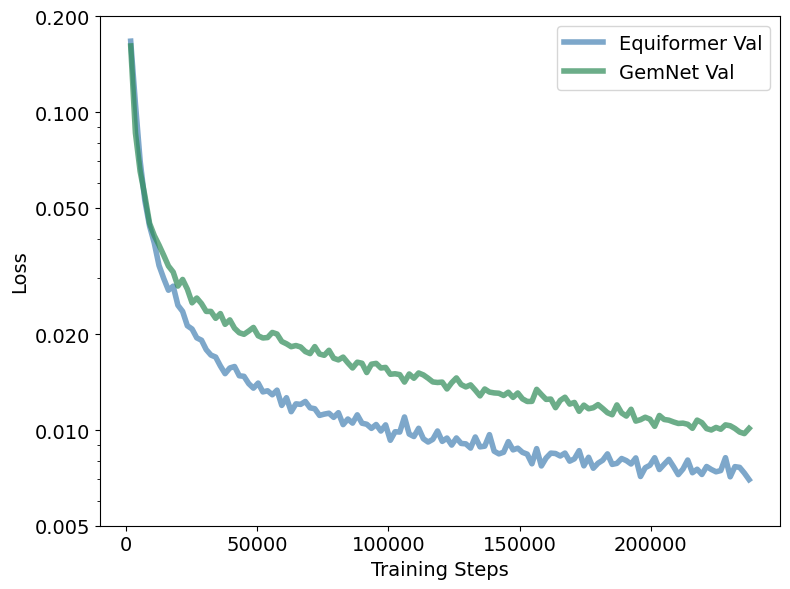

In [15]:
# Read the loss data
df = pd.read_csv('gemnet_equv2_loss.csv')

# Extract columns
steps = df['trainer/global_step']
equiformer_train_loss = df['equiformer-base - train/loss_epoch']
equiformer_val_loss = df['equiformer-base - val/loss']
gemnet_train_loss = df['gemnet-oc - train/loss_epoch']
gemnet_val_loss = df['gemnet-oc - val/loss']

# Find last valid index for equiformer data
last_valid_idx = equiformer_train_loss.last_valid_index()

# Plot training and validation loss curves
fig, ax = plt.subplots(figsize=(8, 6))

# Validation losses (dashed lines)
ax.plot(steps[:last_valid_idx+1], equiformer_val_loss[:last_valid_idx+1], label='Equiformer Val', color='steelblue', linewidth=4, alpha=0.7)
ax.plot(steps[:last_valid_idx+1], gemnet_val_loss[:last_valid_idx+1], label='GemNet Val', color='seagreen', linewidth=4, alpha=0.7)

ax.set_yscale('log')
ax.set_yticks([0.005, 0.01, 0.02, 0.05, 0.1, 0.2])
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.3f}'))
ax.set_xlabel('Training Steps', fontsize=14)
ax.set_ylabel('Loss', fontsize=14)
ax.legend(fontsize=14)
ax.tick_params(axis='both', labelsize=14)
plt.tight_layout()

plt.savefig('plots/gemnet_equv2_loss.pdf', dpi=300, bbox_inches='tight')

# Validation performance 

## In distribution (ID)

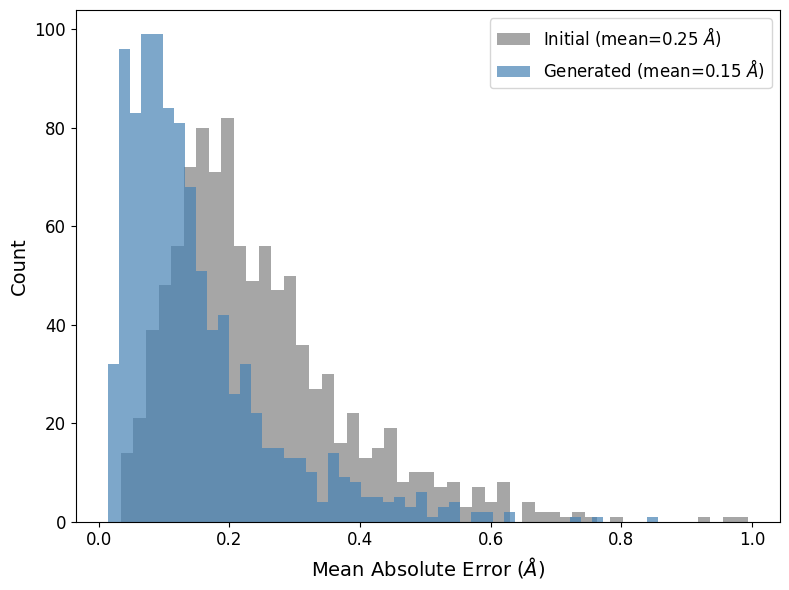

In [3]:
# Load test set metrics
initial_mae = np.load('val_id-metrics/initial_mae.npy')
generated_mae = np.load('val_id-metrics/generated_mae.npy')

# Create histogram for MAE
fig, ax = plt.subplots(figsize=(8, 6))

ax.hist(initial_mae, bins=50, alpha=0.7, label=f'Initial (mean={initial_mae.mean():.2f} $\AA$)', color='grey')
ax.hist(generated_mae, bins=50, alpha=0.7, label=f'Generated (mean={generated_mae.mean():.2f} $\AA$)', color='steelblue')
ax.set_xlabel('Mean Absolute Error ($\AA$)', fontsize=14)
ax.set_ylabel('Count', fontsize=14)
ax.legend(fontsize=12)
ax.tick_params(axis='both', labelsize=12)

plt.tight_layout()
plt.savefig('plots/val_id_mae_histogram.pdf', dpi=300, bbox_inches='tight')
plt.show()

## Out of distribution (OOD)

- ***EquiformerV2 lowers the MAE of an initial structure by 0.08 A, with a total MAE of 0.12 A, across all structures***

- ***The adsorbates show a much higher MAE, as exected. This can be due to (1) the model not learning the MAE well, but also these atoms are known to move the most during a relaxation, indicated by the initial MAE which is a measure of how much an atom moves during a relaxation... the centrail question is whether this is a fault of the model or the dataset***


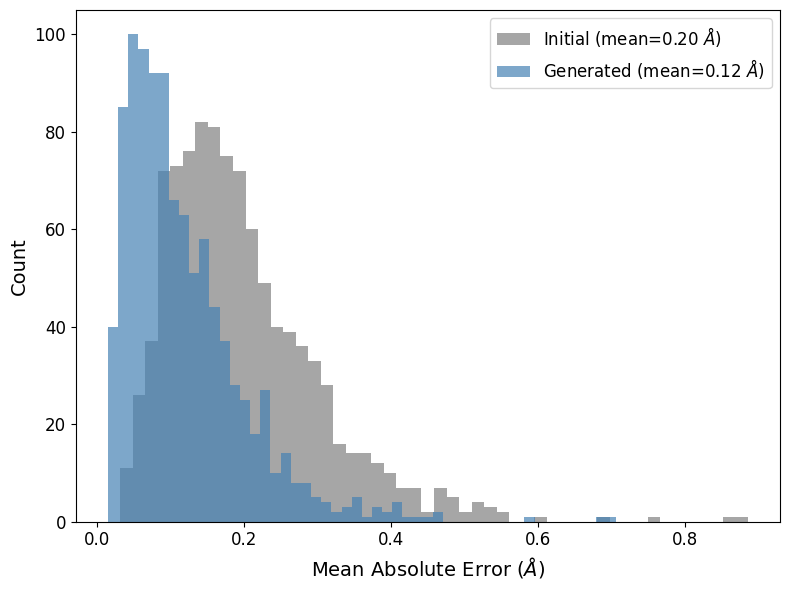

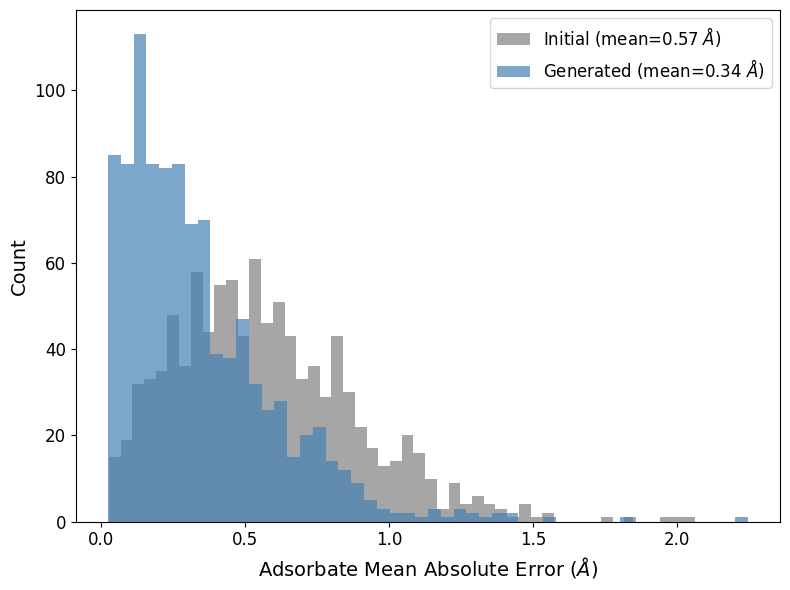

In [19]:
# Load test set metrics
initial_mae = np.load('val_ood_both_base-metrics/initial_mae.npy')
generated_mae = np.load('val_ood_both_base-metrics/generated_mae.npy')

# Create histogram for MAE
fig, ax = plt.subplots(figsize=(8, 6))

ax.hist(initial_mae, bins=50, alpha=0.7, label=f'Initial (mean={initial_mae.mean():.2f} $\AA$)', color='grey')
ax.hist(generated_mae, bins=50, alpha=0.7, label=f'Generated (mean={generated_mae.mean():.2f} $\AA$)', color='steelblue')
ax.set_xlabel('Mean Absolute Error ($\AA$)', fontsize=14)
ax.set_ylabel('Count', fontsize=14)
ax.legend(fontsize=12)
ax.tick_params(axis='both', labelsize=12)

plt.tight_layout()
plt.savefig('plots/val_ood_both_metrics_mae_histogram.pdf', dpi=300, bbox_inches='tight')
plt.show()

# Load test set metrics
initial_ads_mae = np.load('val_ood_both_base-metrics/initial_ads_mae.npy')
generated_ads_mae = np.load('val_ood_both_base-metrics/generated_ads_mae.npy')

# Create histogram for MAE
fig, ax = plt.subplots(figsize=(8, 6))

ax.hist(initial_ads_mae, bins=50, alpha=0.7, label=f'Initial (mean={initial_ads_mae.mean():.2f} $\AA$)', color='grey')
ax.hist(generated_ads_mae, bins=50, alpha=0.7, label=f'Generated (mean={generated_ads_mae.mean():.2f} $\AA$)', color='steelblue')
ax.set_xlabel('Adsorbate Mean Absolute Error ($\AA$)', fontsize=14)
ax.set_ylabel('Count', fontsize=14)
ax.legend(fontsize=12)
ax.tick_params(axis='both', labelsize=12)

plt.tight_layout()
plt.savefig('plots/val_ood_both_metrics_mae_histogram.pdf', dpi=300, bbox_inches='tight')
plt.show()

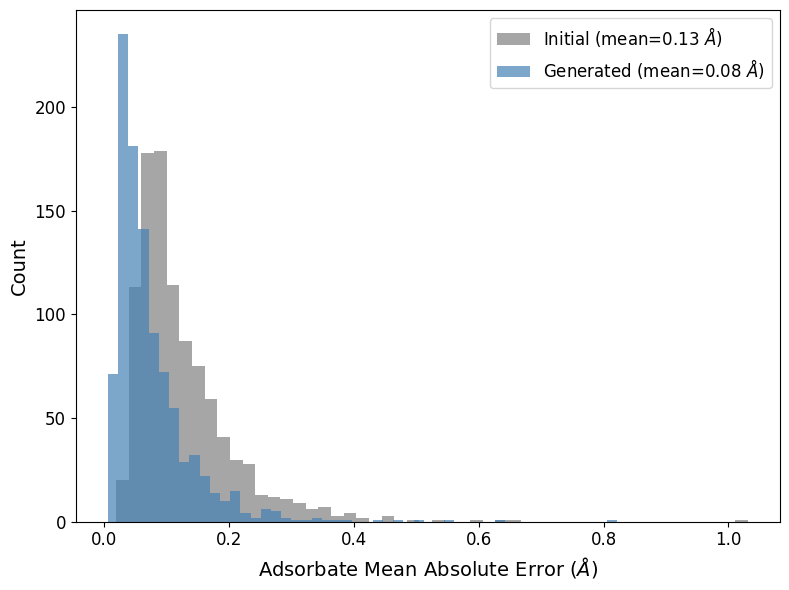

In [28]:
# Load test set metrics
initial_ads_mae = np.load('test_metrics/initial_mae.npy')
generated_ads_mae = np.load('test_metrics/generated_mae.npy')

# Create histogram for MAE
fig, ax = plt.subplots(figsize=(8, 6))

ax.hist(initial_ads_mae, bins=50, alpha=0.7, label=f'Initial (mean={initial_ads_mae.mean():.2f} $\AA$)', color='grey')
ax.hist(generated_ads_mae, bins=50, alpha=0.7, label=f'Generated (mean={generated_ads_mae.mean():.2f} $\AA$)', color='steelblue')
ax.set_xlabel('Adsorbate Mean Absolute Error ($\AA$)', fontsize=14)
ax.set_ylabel('Count', fontsize=14)
ax.legend(fontsize=12)
ax.tick_params(axis='both', labelsize=12)

plt.tight_layout()
plt.savefig('plots/val_ood_both_metrics_mae_histogram.pdf', dpi=300, bbox_inches='tight')
plt.show()

### Mean drift analysis on OOD 

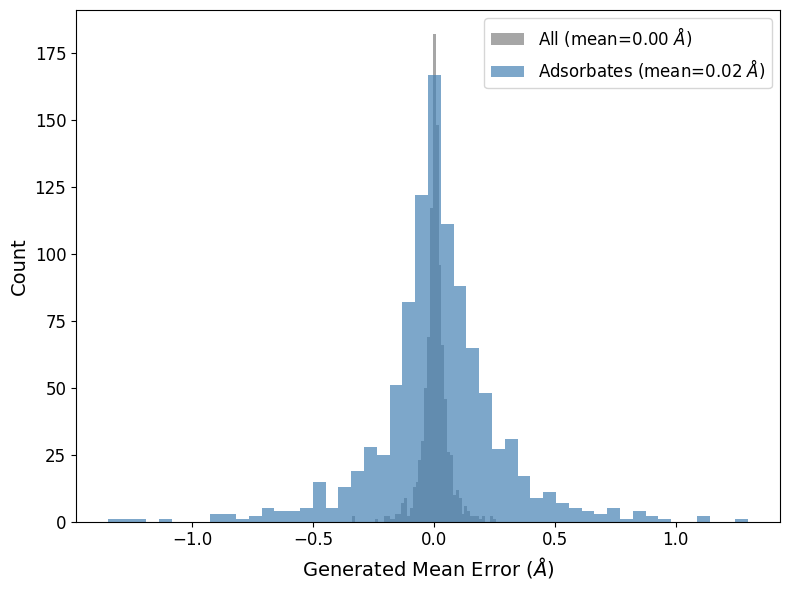

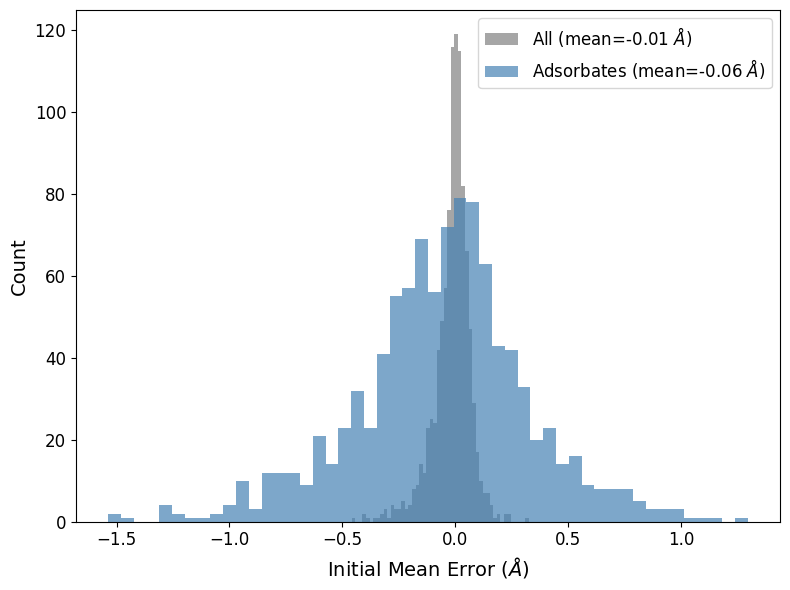

In [22]:
# Load test set metrics
generated_me = np.load('val_ood_both_base-metrics/generated_me.npy')
generated_ads_me = np.load('val_ood_both_base-metrics/generated_ads_me.npy')

# Create histogram for MAE
fig, ax = plt.subplots(figsize=(8, 6))

ax.hist(generated_me, bins=50, alpha=0.7, label=f'All (mean={generated_me.mean():.2f} $\AA$)', color='grey')
ax.hist(generated_ads_me, bins=50, alpha=0.7, label=f'Adsorbates (mean={generated_ads_me.mean():.2f} $\AA$)', color='steelblue')
ax.set_xlabel('Generated Mean Error ($\AA$)', fontsize=14)
ax.set_ylabel('Count', fontsize=14)
ax.legend(fontsize=12)
ax.tick_params(axis='both', labelsize=12)

plt.tight_layout()
plt.savefig('plots/val_ood_both_metrics_mae_histogram.pdf', dpi=300, bbox_inches='tight')

# Load test set metrics
initial_me = np.load('val_ood_both_base-metrics/initial_me.npy')
initial_ads_me = np.load('val_ood_both_base-metrics/initial_ads_me.npy')

# Create histogram for MAE
fig, ax = plt.subplots(figsize=(8, 6))

ax.hist(initial_me, bins=50, alpha=0.7, label=f'All (mean={initial_me.mean():.2f} $\AA$)', color='grey')
ax.hist(initial_ads_me, bins=50, alpha=0.7, label=f'Adsorbates (mean={initial_ads_me.mean():.2f} $\AA$)', color='steelblue')
ax.set_xlabel('Initial Mean Error ($\AA$)', fontsize=14)
ax.set_ylabel('Count', fontsize=14)
ax.legend(fontsize=12)
ax.tick_params(axis='both', labelsize=12)

plt.tight_layout()
plt.savefig('plots/val_ood_both_metrics_mae_histogram.pdf', dpi=300, bbox_inches='tight')

# MLFF

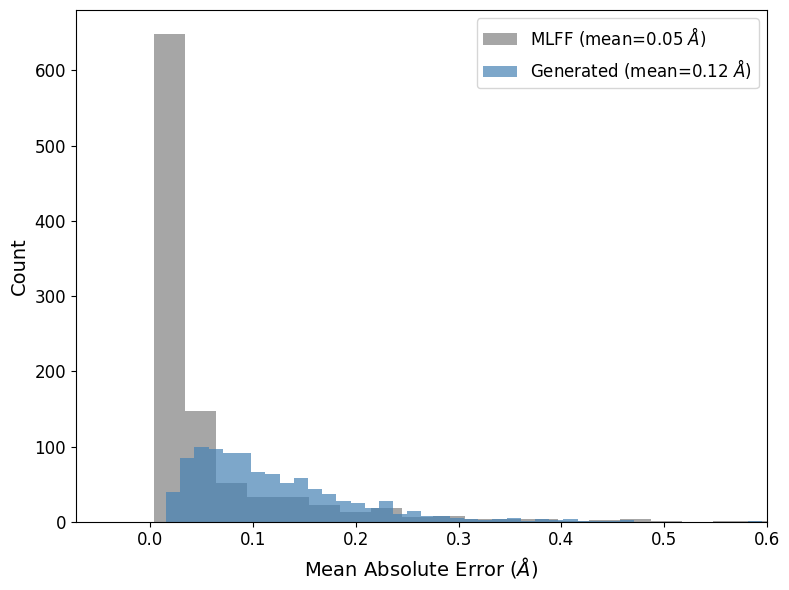

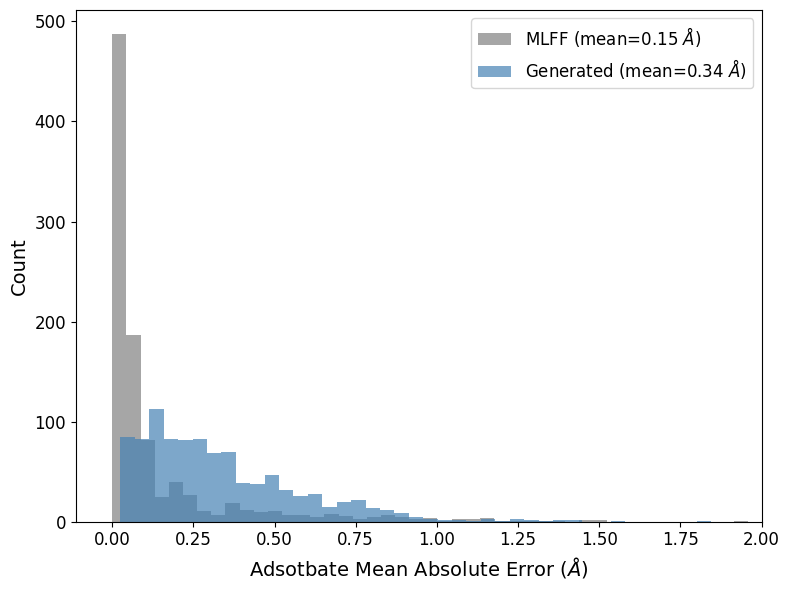

In [24]:
# Load test set metrics
mlff_mae = np.load('mlff_val_data/generated_mae.npy')
generated_mae = np.load('val_ood_both_base-metrics/generated_mae.npy')

# Create histogram for MAE
fig, ax = plt.subplots(figsize=(8, 6))

ax.hist(mlff_mae, bins=50, alpha=0.7, label=f'MLFF (mean={mlff_mae.mean():.2f} $\AA$)', color='grey')
ax.hist(generated_mae, bins=50, alpha=0.7, label=f'Generated (mean={generated_mae.mean():.2f} $\AA$)', color='steelblue')
ax.set_xlabel('Mean Absolute Error ($\AA$)', fontsize=14)
ax.set_ylabel('Count', fontsize=14)
ax.legend(fontsize=12)
ax.tick_params(axis='both', labelsize=12)
ax.set_xlim(None, 0.60)


plt.tight_layout()
plt.savefig('plots/mlff_val_ood_both_metrics_mae_histogram.pdf', dpi=300, bbox_inches='tight')
plt.show()

# Load test set metrics
mlff_ads_mae = np.load('mlff_val_data/generated_ads_mae.npy')
generated_ads_mae = np.load('val_ood_both_base-metrics/generated_ads_mae.npy')

# Create histogram for MAE
fig, ax = plt.subplots(figsize=(8, 6))

ax.hist(mlff_ads_mae, bins=50, alpha=0.7, label=f'MLFF (mean={mlff_ads_mae.mean():.2f} $\AA$)', color='grey')
ax.hist(generated_ads_mae, bins=50, alpha=0.7, label=f'Generated (mean={generated_ads_mae.mean():.2f} $\AA$)', color='steelblue')
ax.set_xlabel('Adsotbate Mean Absolute Error ($\AA$)', fontsize=14)
ax.set_ylabel('Count', fontsize=14)
ax.legend(fontsize=12)
ax.tick_params(axis='both', labelsize=12)
ax.set_xlim(None, 2)


plt.tight_layout()
plt.savefig('plots/mlff_val_ood_both_metrics_mae_histogram.pdf', dpi=300, bbox_inches='tight')
plt.show()

# New models

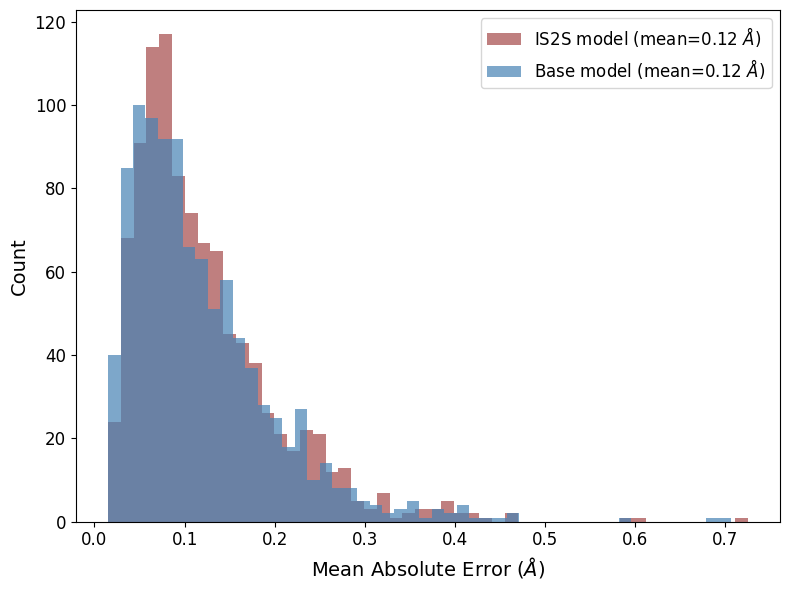

In [8]:
# Load test set metrics
is2s_mae = np.load('is2s_val_ood_both-metrics/generated_mae.npy') 
base_mae = np.load('val_ood_both_base-metrics/generated_mae.npy')

# Create histogram for MAE
fig, ax = plt.subplots(figsize=(8, 6))

ax.hist(is2s_mae, bins=50, alpha=0.5, label=f'IS2S model (mean={is2s_mae.mean():.2f} $\AA$)', color='maroon')
ax.hist(base_mae, bins=50, alpha=0.7, label=f'Base model (mean={base_mae.mean():.2f} $\AA$)', color='steelblue')
ax.set_xlabel('Mean Absolute Error ($\AA$)', fontsize=14)
ax.set_ylabel('Count', fontsize=14)
ax.legend(fontsize=12)
ax.tick_params(axis='both', labelsize=12)

plt.tight_layout()
plt.savefig('plots/val_ood_both_metrics_base_vs_is2s.pdf', dpi=300, bbox_inches='tight')
plt.show()

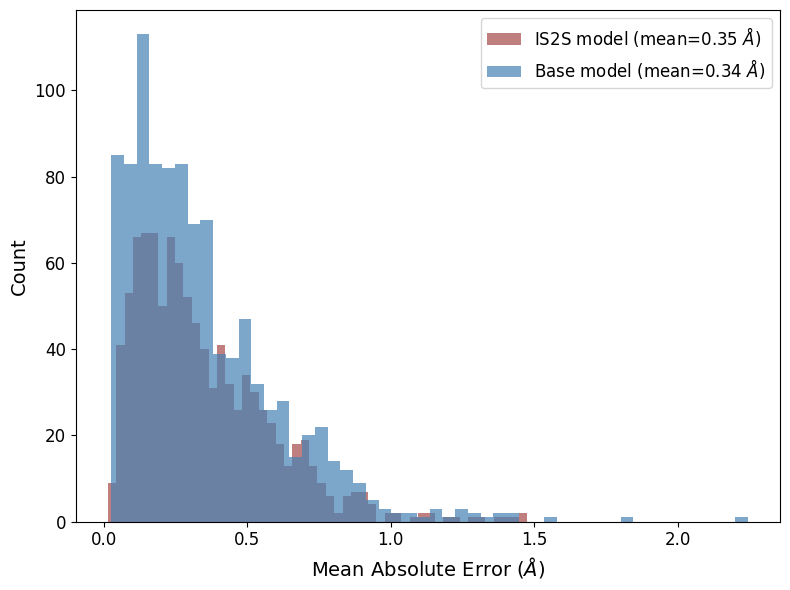

In [9]:
# Load test set metrics
is2s_ads_mae = np.load('is2s_val_ood_both-metrics/generated_ads_mae.npy')
base_ads_mae = np.load('val_ood_both_base-metrics/generated_ads_mae.npy') 

# Create histogram for MAE
fig, ax = plt.subplots(figsize=(8, 6))

ax.hist(is2s_ads_mae, bins=50, alpha=0.5, label=f'IS2S model (mean={is2s_ads_mae.mean():.2f} $\AA$)', color='maroon')
ax.hist(base_ads_mae, bins=50, alpha=0.7, label=f'Base model (mean={base_ads_mae.mean():.2f} $\AA$)', color='steelblue')
ax.set_xlabel('Mean Absolute Error ($\AA$)', fontsize=14)
ax.set_ylabel('Count', fontsize=14)
ax.legend(fontsize=12)
ax.tick_params(axis='both', labelsize=12)

plt.tight_layout()
plt.savefig('plots/val_ood_both_metrics_ads_base_vs_is2s.pdf', dpi=300, bbox_inches='tight')
plt.show()

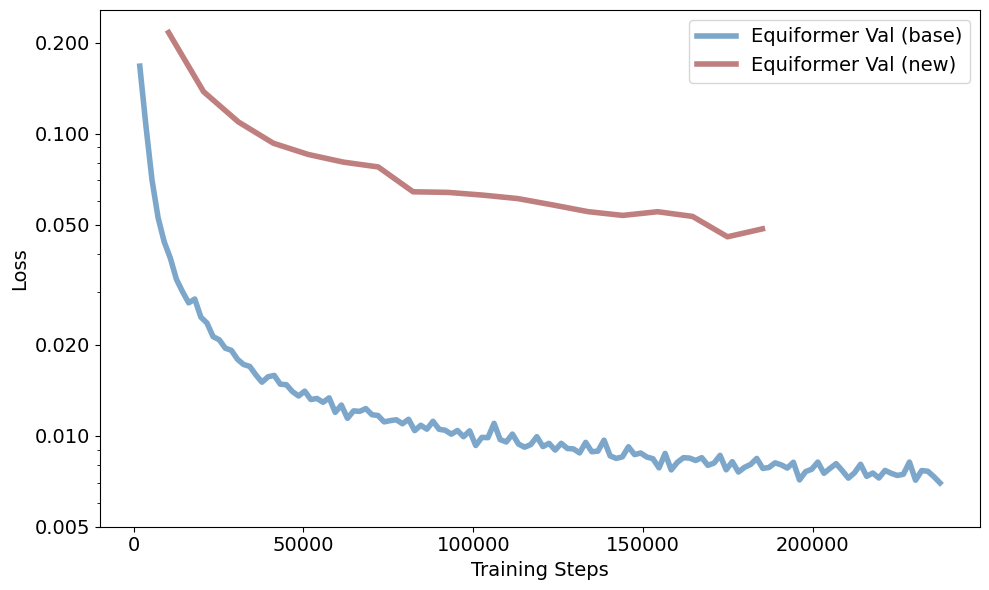

In [10]:
# Read the loss data
df1 = pd.read_csv('gemnet_equv2_loss.csv')
df2 = pd.read_csv('equv2_is2s_flow.csv')

# Extract columns
steps1 = df1['trainer/global_step']
equiformer_val_loss_1 = df1['equiformer-base - val/loss']

steps2 = df2['trainer/global_step']
equiformer_val_loss_2 = df2['equiformer-is2s-flow - val/loss']


# Plot training and validation loss curves
fig, ax = plt.subplots(figsize=(10, 6))

# Validation losses (dashed lines)
ax.plot(steps1, equiformer_val_loss_1, label='Equiformer Val (base)', color='steelblue', linewidth=4, alpha=0.7)
ax.plot(steps2, equiformer_val_loss_2, label='Equiformer Val (new)', color='maroon', linewidth=4, alpha=0.50)

ax.set_yscale('log')
ax.set_yticks([0.005, 0.01, 0.02, 0.05, 0.1, 0.2])
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.3f}'))
ax.set_xlabel('Training Steps', fontsize=14)
ax.set_ylabel('Loss', fontsize=14)
ax.legend(fontsize=14)
ax.tick_params(axis='both', labelsize=14)
plt.tight_layout()

plt.savefig('plots/equv2_base_vs_new_loss.pdf', dpi=300, bbox_inches='tight')

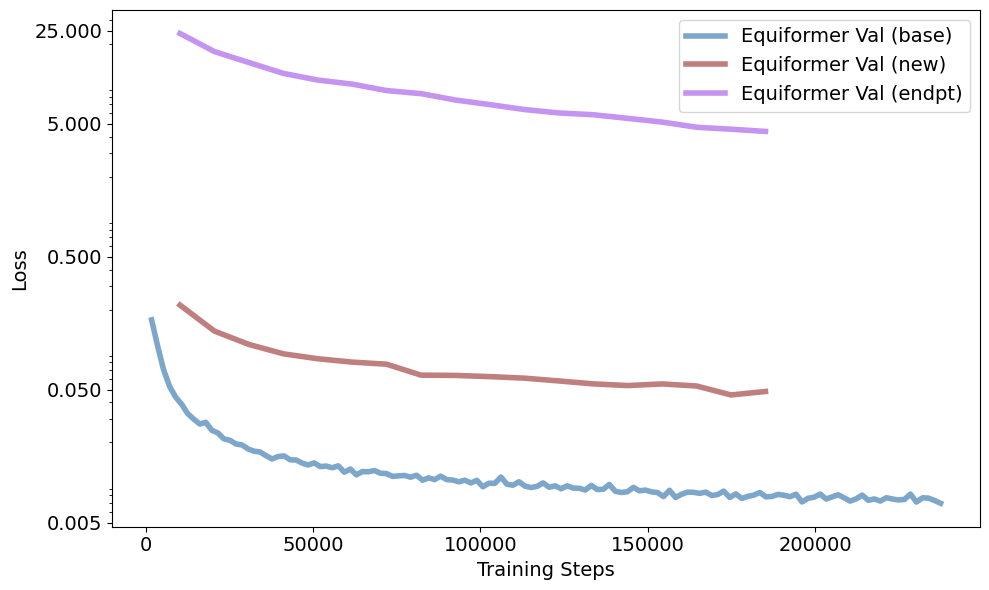

In [11]:
# Read the loss data
df1 = pd.read_csv('gemnet_equv2_loss.csv')
df2 = pd.read_csv('equv2_is2s_flow.csv')
df3 = pd.read_csv('equv2_is2s_endpt.csv')

# Extract columns
steps1 = df1['trainer/global_step']
equiformer_val_loss_1 = df1['equiformer-base - val/loss']

steps2 = df2['trainer/global_step']
equiformer_val_loss_2 = df2['equiformer-is2s-flow - val/loss']

steps3 = df3['trainer/global_step']
equiformer_val_loss_3 = df3['equiformer-is2s-endpt - val/loss']


# Plot training and validation loss curves
fig, ax = plt.subplots(figsize=(10, 6))

# Validation losses (dashed lines)
ax.plot(steps1, equiformer_val_loss_1, label='Equiformer Val (base)', color='steelblue', linewidth=4, alpha=0.7)
ax.plot(steps2, equiformer_val_loss_2, label='Equiformer Val (new)', color='maroon', linewidth=4, alpha=0.50)
ax.plot(steps3, equiformer_val_loss_3, label='Equiformer Val (endpt)', color='blueviolet', linewidth=4, alpha=0.50)

ax.set_yscale('log')
ax.set_yticks([0.005, 0.05, 0.5, 5, 25])
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.3f}'))
ax.set_xlabel('Training Steps', fontsize=14)
ax.set_ylabel('Loss', fontsize=14)
ax.legend(fontsize=14)
ax.tick_params(axis='both', labelsize=14)
plt.tight_layout()

plt.savefig('plots/equv2_base_vs_new_vs_endpt_loss.pdf', dpi=300, bbox_inches='tight')

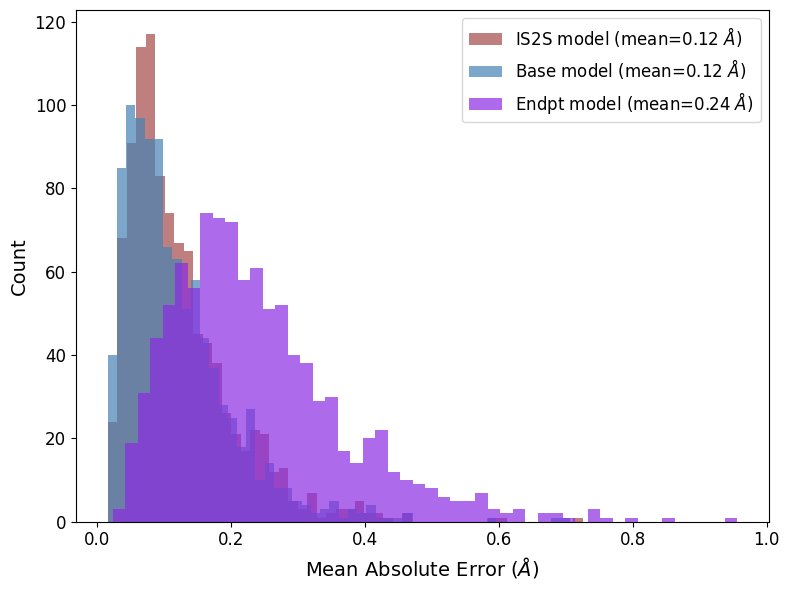

In [12]:
# Load test set metrics
is2s_mae = np.load('is2s_val_ood_both-metrics/generated_mae.npy') 
base_mae = np.load('val_ood_both_base-metrics/generated_mae.npy')
endpt_mae = np.load('val_ood_both_endpt-metrics/generated_mae.npy')

# Create histogram for MAE
fig, ax = plt.subplots(figsize=(8, 6))

ax.hist(is2s_mae, bins=50, alpha=0.5, label=f'IS2S model (mean={is2s_mae.mean():.2f} $\AA$)', color='maroon')
ax.hist(base_mae, bins=50, alpha=0.7, label=f'Base model (mean={base_mae.mean():.2f} $\AA$)', color='steelblue')
ax.hist(endpt_mae, bins=50, alpha=0.7, label=f'Endpt model (mean={endpt_mae.mean():.2f} $\AA$)', color='blueviolet')

ax.set_xlabel('Mean Absolute Error ($\AA$)', fontsize=14)
ax.set_ylabel('Count', fontsize=14)
ax.legend(fontsize=12)
ax.tick_params(axis='both', labelsize=12)

plt.tight_layout()
plt.savefig('plots/val_ood_both_metrics_base_vs_is2s_vs_endpt.pdf', dpi=300, bbox_inches='tight')
plt.show()